In [1]:
import pandas as pd
import numpy as np

from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split

## Import Data

In [2]:
df = pd.read_csv("../00_Data/Output/merged_road_collisions_5y.csv", dtype={"collision_index": str})
print(f"Shape: {df.shape}")

Shape: (513745, 145)


## Leak

In [3]:
## Esclusione variabili (leak e non note al centralino)

# leak: la presenza della polizia dipende dalla gravità
leak = [c for c in df.columns if c.startswith("did_police_officer_attend_scene_of_accident")]

DROP_MOTIVI = {
    "journey_purpose_of_driver_": "chi chiama non sa perché stava guidando l'altro conducente",
    "driver_imd_decile_":         "deriva dal codice postale del conducente: non noto a chi chiama",
    "propulsion_code_":           "dopo un incidente non si sa se l'altra auto è a gasolio o a benzina",
}

rows, drop_cols = [{"gruppo": "did_police_officer_attend_*", "n_colonne": len(leak), "motivo": "leak"}], list(leak)
for pref, motivo in DROP_MOTIVI.items():
    cols = [c for c in df.columns if c.startswith(pref)]
    drop_cols += cols
    rows.append({"gruppo": pref, "n_colonne": len(cols), "motivo": motivo})

display(pd.DataFrame(rows))
df = df.drop(columns=drop_cols)
print(f"Rimosse {len(drop_cols)} colonne | df.shape: {df.shape}")

,gruppo,n_colonne,motivo
0,did_police_officer_attend_*,3,leak
1,journey_purpose_of_driver_,3,chi chiama non sa perché stava guidando l'altr...
2,driver_imd_decile_,5,deriva dal codice postale del conducente: non ...
3,propulsion_code_,4,dopo un incidente non si sa se l'altra auto è ...


Rimosse 15 colonne | df.shape: (513745, 130)


## Correlations

In [4]:
excl = {"collision_year", "longitude", "latitude", "date", "month", "speed_limit",
        "number_of_vehicles", "number_of_casualties", "age_of_casualty_mean", "collision_severity"}
cand = [c for c in df.select_dtypes("number").columns if c not in excl]

s = df[cand].astype("float32")
s = s.loc[:, s.std() > 0]
C = np.corrcoef(s.values, rowvar=False)

THR = 0.85   # abbassalo per vedere più coppie
for i, j in zip(*np.triu_indices(len(s.columns), k=1)):
    if abs(C[i, j]) >= THR:
        print(f"{C[i, j]:+.4f} | {s.columns[i]}  <->  {s.columns[j]}")

-1.0000 | day_of_week_Weekday  <->  day_of_week_Weekend
-0.9108 | road_surface_conditions_Dry  <->  road_surface_conditions_Wet or flooded
-1.0000 | urban_or_rural_area_Rural  <->  urban_or_rural_area_Urban
+0.9916 | vehicle_type_E-scooter / PPT  <->  escooter_flag_Vehicle was an e-scooter
+0.8740 | vehicle_type_E-scooter / PPT  <->  casualty_type_E-scooter / PPT
+0.9485 | vehicle_type_Motorcycle over 125cc  <->  casualty_type_Motorcycle over 125cc
+0.9351 | vehicle_type_Motorcycle up to 125cc  <->  casualty_type_Motorcycle up to 125cc
+0.9684 | vehicle_type_Pedal cycle  <->  casualty_type_Pedal cycle
+0.8718 | vehicle_location_restricted_lane_Main carriageway  <->  hit_object_in_carriageway_None
+0.8586 | vehicle_location_restricted_lane_Main carriageway  <->  hit_object_off_carriageway_None
+0.8582 | hit_object_in_carriageway_None  <->  hit_object_off_carriageway_None
+0.9250 | vehicle_leaving_carriageway_Did not leave carriageway  <->  hit_object_off_carriageway_None
+0.8679 | escoo

In [5]:
n_pos = (df[s.columns] > 0).sum()   # prevalenza di ogni colonna

pairs = [(abs(C[i, j]), s.columns[i], s.columns[j])
         for i, j in zip(*np.triu_indices(len(s.columns), k=1))
         if abs(C[i, j]) >= THR]

to_drop = set()
for r, a, b in sorted(pairs, reverse=True):
    if a in to_drop or b in to_drop:
        continue                      # coppia già risolta (catena)
    drop = a if n_pos[a] < n_pos[b] else b
    to_drop.add(drop)
    print(f"{r:.4f} | tieni: {b if drop == a else a}  |  droppa: {drop}")

print("\nLista da droppare:")
print(sorted(to_drop))

1.0000 | tieni: casualty_class_Pedestrian  |  droppa: casualty_type_Pedestrian
1.0000 | tieni: day_of_week_Weekday  |  droppa: day_of_week_Weekend
1.0000 | tieni: urban_or_rural_area_Urban  |  droppa: urban_or_rural_area_Rural
0.9916 | tieni: vehicle_type_E-scooter / PPT  |  droppa: escooter_flag_Vehicle was an e-scooter
0.9684 | tieni: vehicle_type_Pedal cycle  |  droppa: casualty_type_Pedal cycle
0.9485 | tieni: vehicle_type_Motorcycle over 125cc  |  droppa: casualty_type_Motorcycle over 125cc
0.9351 | tieni: vehicle_type_Motorcycle up to 125cc  |  droppa: casualty_type_Motorcycle up to 125cc
0.9250 | tieni: hit_object_off_carriageway_None  |  droppa: vehicle_leaving_carriageway_Did not leave carriageway
0.9108 | tieni: road_surface_conditions_Dry  |  droppa: road_surface_conditions_Wet or flooded
0.8740 | tieni: vehicle_type_E-scooter / PPT  |  droppa: casualty_type_E-scooter / PPT
0.8718 | tieni: vehicle_location_restricted_lane_Main carriageway  |  droppa: hit_object_in_carriagewa

Nota sulle catene: la stampa riga per riga mostra la scelta coppia per coppia.
`hit_object_off_carriageway_None` compare come "tieni" nella coppia con
`vehicle_leaving_carriageway_Did not leave carriageway` (r = 0,925), ma viene poi eliminata
nella coppia con `vehicle_location_restricted_lane_Main carriageway` (r = 0,859).
Le tre variabili sono legate a catena, quindi l'informazione resta in
`vehicle_location_restricted_lane_Main carriageway`. L'elenco definitivo è quello
della cella successiva ("Tenute" / "Eliminate").

In [6]:
kept = sorted({x for _, a, b in pairs for x in (a, b)} - to_drop)
print("Tenute:", kept)
print("Eliminate:", sorted(to_drop))

Tenute: ['casualty_class_Pedestrian', 'day_of_week_Weekday', 'road_surface_conditions_Dry', 'urban_or_rural_area_Urban', 'vehicle_location_restricted_lane_Main carriageway', 'vehicle_type_E-scooter / PPT', 'vehicle_type_Motorcycle over 125cc', 'vehicle_type_Motorcycle up to 125cc', 'vehicle_type_Pedal cycle']
Eliminate: ['casualty_type_E-scooter / PPT', 'casualty_type_Motorcycle over 125cc', 'casualty_type_Motorcycle up to 125cc', 'casualty_type_Pedal cycle', 'casualty_type_Pedestrian', 'day_of_week_Weekend', 'escooter_flag_Vehicle was an e-scooter', 'hit_object_in_carriageway_None', 'hit_object_off_carriageway_None', 'road_surface_conditions_Wet or flooded', 'urban_or_rural_area_Rural', 'vehicle_leaving_carriageway_Did not leave carriageway']


In [7]:
# drop
print(f"Dimensione prima del drop variabili correlate: {df.shape}")
df.drop(columns=to_drop, inplace=True)
print(f"Colonne eliminate: {len(to_drop)}")
print(f"Dimensione dopo il drop variabili correlate: {df.shape}")

Dimensione prima del drop variabili correlate: (513745, 130)
Colonne eliminate: 12
Dimensione dopo il drop variabili correlate: (513745, 118)


In [8]:
df.head()

,collision_index,collision_year,longitude,latitude,collision_severity,number_of_vehicles,number_of_casualties,date,speed_limit,collision_injury_based,...,pedestrian_movement_Crossing,pedestrian_movement_Crossing - masked,pedestrian_movement_Stationary in carriageway,pedestrian_movement_Walking along carriageway,casualty_type_Bus or minibus,casualty_type_Car,casualty_type_HGV,casualty_type_Other,casualty_type_Van,age_of_casualty_mean
0,202417H105824,2024,-1.24700,54.69840,Serious,2,1,2024-10-03,30,1,...,0,0,0,0,0,0,0,0,0,33.000000
1,202517M115025,2025,-1.19147,54.56387,Serious,2,1,2025-11-29,30,1,...,0,0,0,0,0,0,0,0,0,17.000000
2,202517L306225,2025,-1.08390,54.60600,Slight,2,3,2025-06-01,30,1,...,0,0,0,0,0,2,0,0,1,19.666667
3,202417S104724,2024,-1.37599,54.55157,Slight,2,2,2024-04-20,60,1,...,0,0,0,0,0,2,0,0,0,23.500000
4,202517S106525,2025,-1.31596,54.56228,Serious,2,1,2025-05-16,30,1,...,0,0,0,0,0,0,0,0,0,16.000000


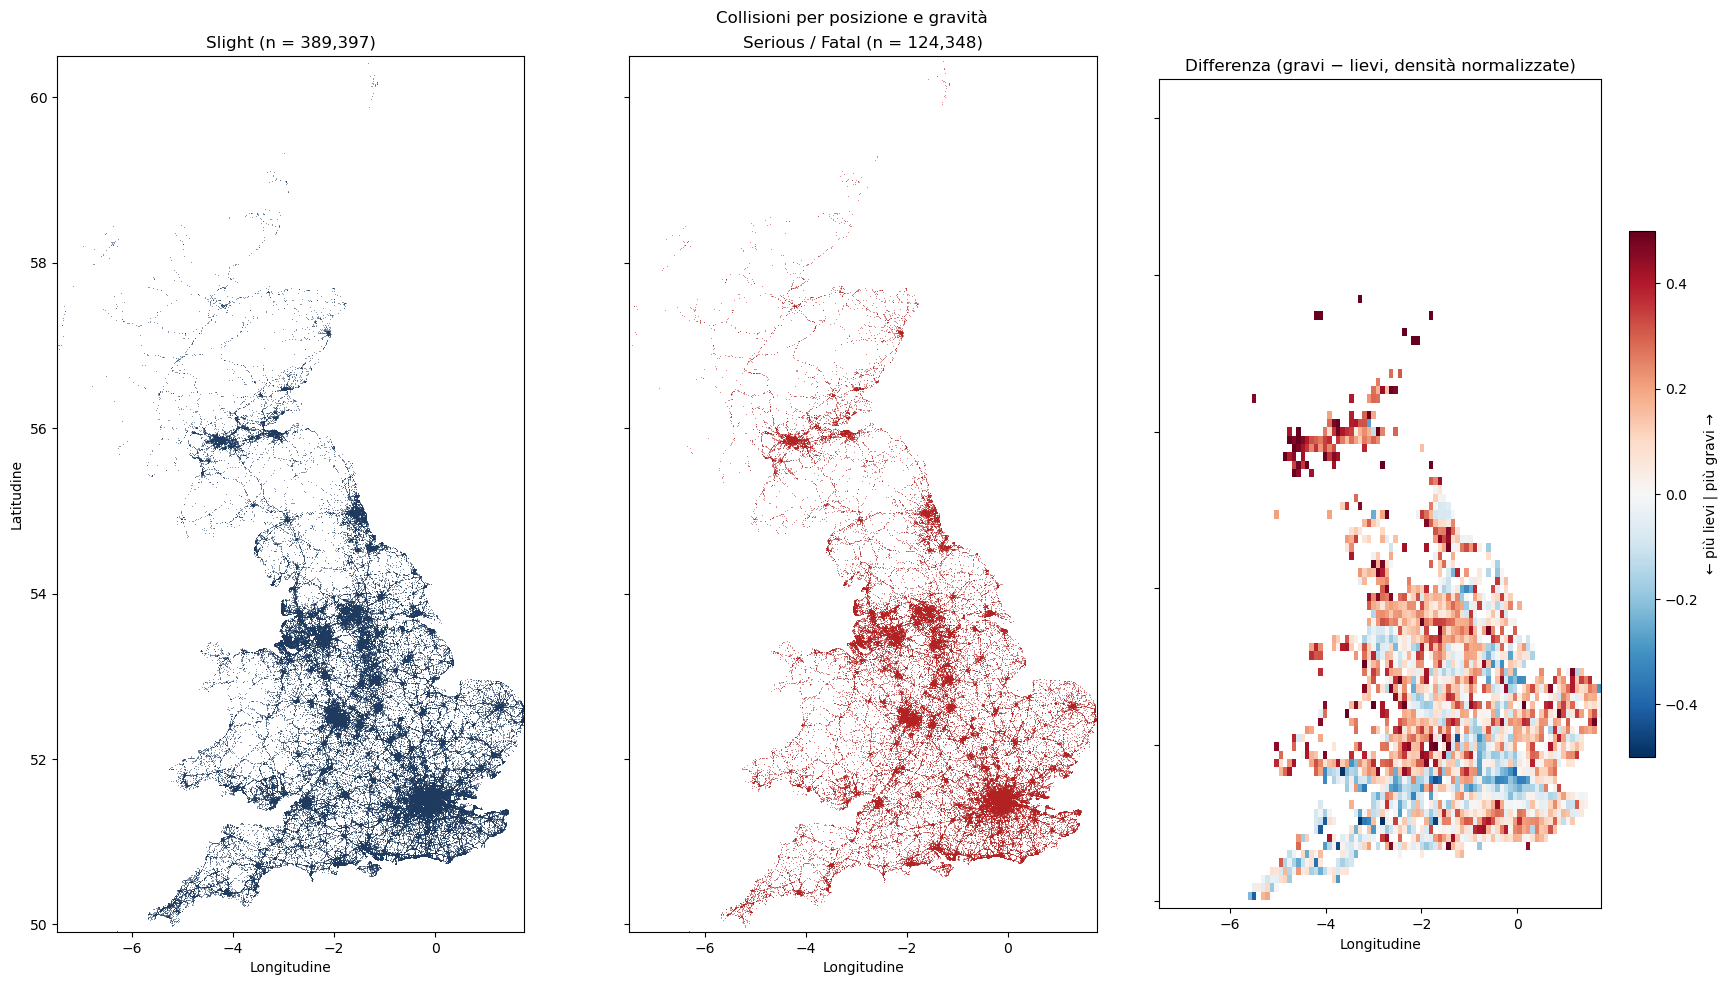

In [9]:
import matplotlib.pyplot as plt

sev = df["collision_severity"].isin(["Fatal", "Serious"])
lon, lat = df["longitude"], df["latitude"]
asp = 1 / np.cos(np.deg2rad(lat.mean()))

# --- differenza tra densità normalizzate
bins = 100
rng = [[lon.min(), lon.max()], [lat.min(), lat.max()]]
H1, xe, ye = np.histogram2d(lon[sev], lat[sev], bins=bins, range=rng)
H0, _, _ = np.histogram2d(lon[~sev], lat[~sev], bins=bins, range=rng)
p1, p0 = H1 / H1.sum(), H0 / H0.sum()
with np.errstate(invalid="ignore", divide="ignore"):
    D = (p1 - p0) / (p1 + p0)                   # +1 solo gravi, -1 solo lievi, 0 stessa densità
D = np.where((H1 + H0) >= 30, D, np.nan)        # nasconde le celle con poche collisioni
lim = 0.5

# --- figura
fig, axes = plt.subplots(1, 3, figsize=(18, 10), sharex=True, sharey=True)

for ax, mask, color, title in [
    (axes[0], ~sev, "#1F3A5F", f"Slight (n = {(~sev).sum():,})"),
    (axes[1], sev, "#B22222", f"Serious / Fatal (n = {sev.sum():,})"),
]:
    ax.scatter(lon[mask], lat[mask], s=0.5, c=color, alpha=0.4, linewidths=0, rasterized=True)
    ax.set_title(title)

im = axes[2].pcolormesh(xe, ye, D.T, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[2].set_title("Differenza (gravi − lievi, densità normalizzate)")
fig.colorbar(im, ax=axes[2], shrink=0.6, label="← più lievi | più gravi →")

for ax in axes:
    ax.set_aspect(asp)
    ax.set_xlabel("Longitudine")
axes[0].set_ylabel("Latitudine")

fig.suptitle("Collisioni per posizione e gravità")
plt.tight_layout()
plt.savefig("../02_Output_grafici/02_map.png", dpi=200, bbox_inches="tight")   # opzionale
plt.show()

## NZV Deletion

In [10]:
# nzv check

selector = VarianceThreshold(threshold=0.01)
selector.fit(df.select_dtypes(include=['float64', 'int64']))
print("Features with low variance (below threshold):")
low_variance_features = df.select_dtypes(include=['float64', 'int64']).columns[~selector.get_support()]
print(low_variance_features)
print("Number of features with low variance:", len(low_variance_features))

Features with low variance (below threshold):
Index(['pedestrian_crossing_Footbridge or subway', 'weather_conditions_Snow',
       'casualty_type_HGV'],
      dtype='str')
Number of features with low variance: 3


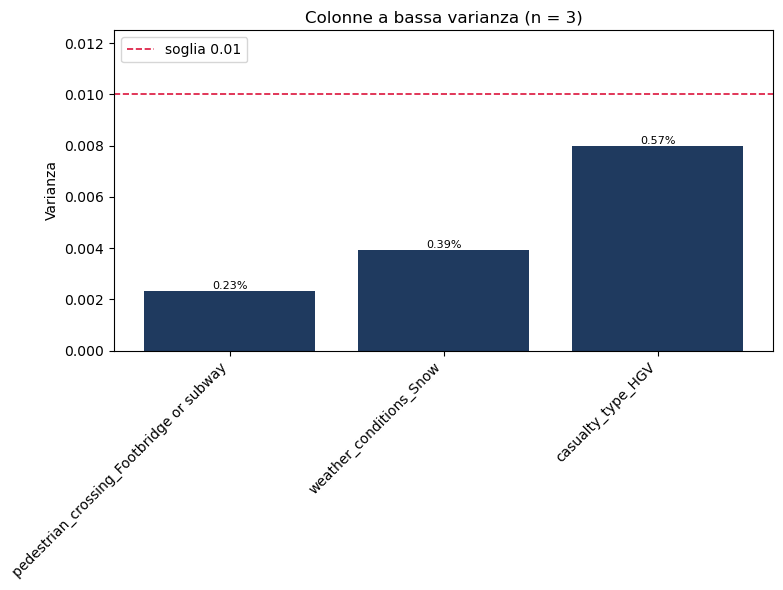

In [11]:
import matplotlib.pyplot as plt

num = df.select_dtypes(include=["float64", "int64"])
var = num.var(ddof=0)                         # stessa varianza usata da VarianceThreshold
low = var[low_variance_features].sort_values()
prev = (df[low.index] > 0).mean() * 100       # % di righe in cui la colonna è presente

fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(low)), 6))
bars = ax.bar(low.index, low.values, color="#1F3A5F")
ax.axhline(0.01, color="crimson", ls="--", lw=1.2, label="soglia 0.01")
for bar, p in zip(bars, prev):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{p:.2f}%", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, 0.0125)
ax.set_ylabel("Varianza")
ax.set_title(f"Colonne a bassa varianza (n = {len(low)})")
ax.legend(loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../02_Output_grafici/02_nzv_variance.png", dpi=200, bbox_inches="tight")   # opzionale
plt.show()

In [12]:
low_var = low_variance_features.tolist()
df = df.drop(columns=low_var)
print(f"Eliminate {len(low_var)} colonne NZV | df.shape: {df.shape}")

Eliminate 3 colonne NZV | df.shape: (513745, 115)


In [13]:
df.head()

,collision_index,collision_year,longitude,latitude,collision_severity,number_of_vehicles,number_of_casualties,date,speed_limit,collision_injury_based,...,pedestrian_location_On footway or verge,pedestrian_movement_Crossing,pedestrian_movement_Crossing - masked,pedestrian_movement_Stationary in carriageway,pedestrian_movement_Walking along carriageway,casualty_type_Bus or minibus,casualty_type_Car,casualty_type_Other,casualty_type_Van,age_of_casualty_mean
0,202417H105824,2024,-1.24700,54.69840,Serious,2,1,2024-10-03,30,1,...,0,0,0,0,0,0,0,0,0,33.000000
1,202517M115025,2025,-1.19147,54.56387,Serious,2,1,2025-11-29,30,1,...,0,0,0,0,0,0,0,0,0,17.000000
2,202517L306225,2025,-1.08390,54.60600,Slight,2,3,2025-06-01,30,1,...,0,0,0,0,0,0,2,0,1,19.666667
3,202417S104724,2024,-1.37599,54.55157,Slight,2,2,2024-04-20,60,1,...,0,0,0,0,0,0,2,0,0,23.500000
4,202517S106525,2025,-1.31596,54.56228,Serious,2,1,2025-05-16,30,1,...,0,0,0,0,0,0,0,0,0,16.000000


In [14]:
nan = df.isna().sum()
nan = nan[nan > 0]
print("\nColonne con NaN:" if len(nan) else "\nNessun NaN nel df")
if len(nan):
    display(pd.DataFrame({"n_nan": nan, "%": (nan / len(df) * 100).round(2)}))


Colonne con NaN:


,n_nan,%
age_of_casualty_mean,8392,1.63


## Target Creation

In [15]:
# creazione del target binario
df = df.copy()
df["collision_severity_bin"] = df["collision_severity"].isin(["Fatal", "Serious"]).astype(int)
df.drop(columns=["collision_severity"], inplace=True)

 controllo  variabili date

In [16]:
df = df.copy()
# creazione colonna woy (week of year) per lo split stratificato
df["woy"] = pd.to_datetime(df["date"]).dt.isocalendar().week.astype("int32")
# drop dell'anno e della data, che non servono più
df.drop(columns=["collision_year", "date", "month"], inplace=True)
df["woy"] = df["woy"].replace(53, 1)

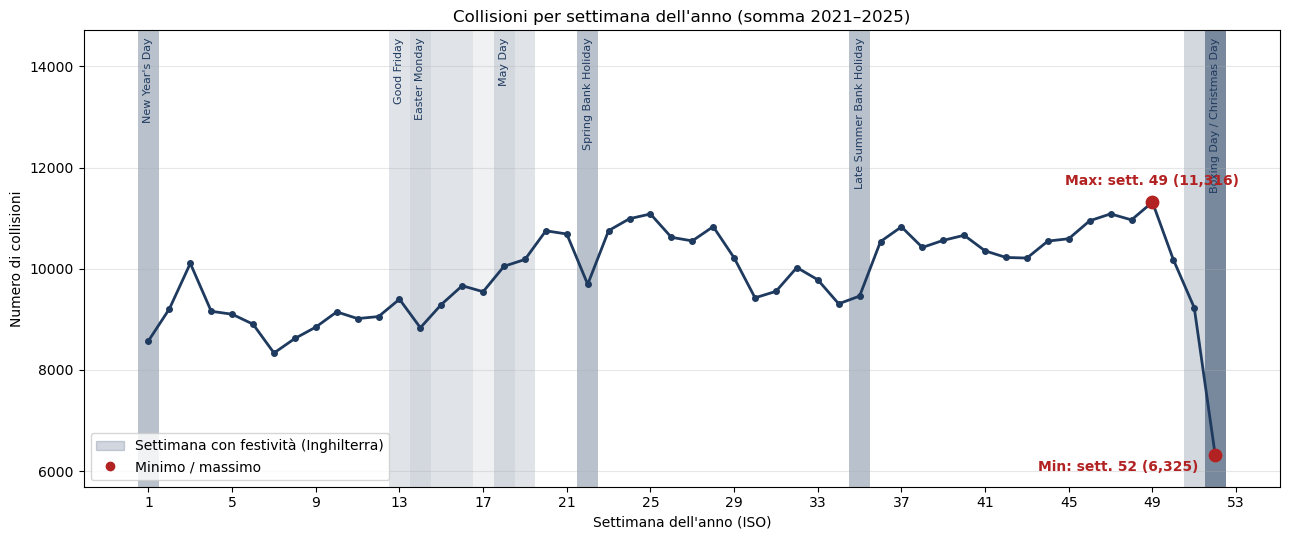

In [17]:
import holidays
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

NAVY, RED = "#1F3A5F", "#B22222"
cnt = df["woy"].replace(53, 1).value_counts().sort_index()

# --- festività inglesi 2021-2025 -> settimana ISO (53 accorpata alla 1)
hol = holidays.country_holidays("GB", subdiv="ENG", years=range(2021, 2026))
h = pd.DataFrame([(n.replace(" (observed)", ""), pd.Timestamp(d).isocalendar().week) for d, n in hol.items()],
                 columns=["nome", "sett"])
h["sett"] = h["sett"].replace(53, 1)
h = h[h.groupby("nome")["nome"].transform("size") >= 3]       # scarta le festività una tantum (Giubileo, funerale, incoronazione)
mode_week = h.groupby("nome")["sett"].agg(lambda s: s.mode().iloc[0])

fig, ax = plt.subplots(figsize=(13, 5.5))

# bande: una per ogni occorrenza, si sovrappongono dove la festività cade nella stessa settimana in più anni
for w in h["sett"]:
    ax.axvspan(w - 0.5, w + 0.5, color=NAVY, alpha=0.07, lw=0)

ax.plot(cnt.index, cnt.values, color=NAVY, lw=2, marker="o", ms=4, zorder=3)

# etichette festività, raggruppate per settimana
for w, nomi in mode_week.groupby(mode_week).groups.items():
    ax.text(w, 0.985, " / ".join(nomi), transform=ax.get_xaxis_transform(), rotation=90,
            va="top", ha="center", fontsize=8, color=NAVY)

# min e max
imax, imin = cnt.idxmax(), cnt.idxmin()
ax.scatter([imax, imin], [cnt[imax], cnt[imin]], color=RED, s=80, zorder=5)
ax.annotate(f"Max: sett. {imax} ({cnt[imax]:,})", (imax, cnt[imax]), xytext=(0, 12),
            textcoords="offset points", ha="center", color=RED, fontweight="bold")
ax.annotate(f"Min: sett. {imin} ({cnt[imin]:,})", (imin, cnt[imin]), xytext=(-12, -4),
            textcoords="offset points", ha="right", va="top", color=RED, fontweight="bold")

ax.set_ylim(cnt.min() * 0.9, cnt.max() * 1.3)                 # spazio per le etichette
ax.set_xticks(range(1, 54, 4))
ax.set_xlabel("Settimana dell'anno (ISO)")
ax.set_ylabel("Numero di collisioni")
ax.set_title("Collisioni per settimana dell'anno (somma 2021–2025)")
ax.grid(axis="y", alpha=0.3)
ax.legend(handles=[Patch(color=NAVY, alpha=0.2, label="Settimana con festività (Inghilterra)"),
                   plt.Line2D([], [], color=RED, marker="o", ls="", label="Minimo / massimo")],
          loc="lower left")
plt.tight_layout()
plt.savefig("../02_Output_grafici/02_collisions_by_woy.png", dpi=300, bbox_inches="tight")
plt.show()

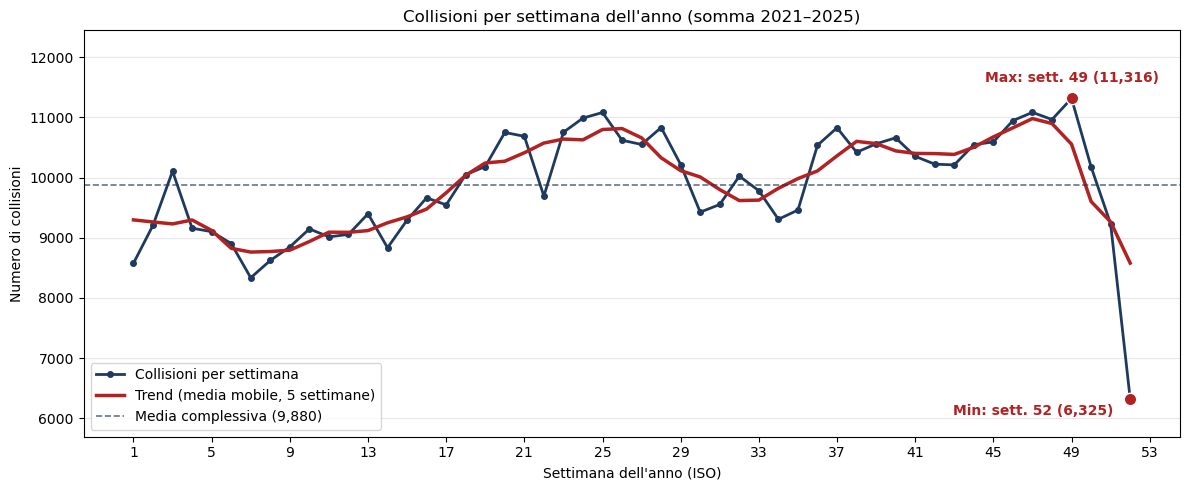

In [18]:
import matplotlib.pyplot as plt

NAVY, RED = "#1F3A5F", "#B22222"
cnt = df["woy"].replace(53, 1).value_counts().sort_index()

trend = cnt.rolling(window=5, center=True, min_periods=1).mean()   # media mobile su 5 settimane
media = cnt.mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(cnt.index, cnt.values, color=NAVY, lw=2, marker="o", ms=4, label="Collisioni per settimana")
ax.plot(trend.index, trend.values, color=RED, lw=2.5, label="Trend (media mobile, 5 settimane)")
ax.axhline(media, color=NAVY, ls="--", lw=1.2, alpha=0.7, label=f"Media complessiva ({media:,.0f})")

# min e max
imax, imin = cnt.idxmax(), cnt.idxmin()
ax.scatter([imax, imin], [cnt[imax], cnt[imin]], color=RED, s=80, zorder=5, edgecolor="white")
ax.annotate(f"Max: sett. {imax} ({cnt[imax]:,})", (imax, cnt[imax]), xytext=(0, 12),
            textcoords="offset points", ha="center", color=RED, fontweight="bold")
ax.annotate(f"Min: sett. {imin} ({cnt[imin]:,})", (imin, cnt[imin]), xytext=(-12, -4),
            textcoords="offset points", ha="right", va="top", color=RED, fontweight="bold")

ax.set_ylim(cnt.min() * 0.9, cnt.max() * 1.1)
ax.set_xticks(range(1, 54, 4))
ax.set_xlabel("Settimana dell'anno (ISO)")
ax.set_ylabel("Numero di collisioni")
ax.set_title("Collisioni per settimana dell'anno (somma 2021–2025)")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig("../02_Output_grafici/02_collisions_by_woy_trend.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
print("Righe:", len(df), "| collisioni uniche:", df["collision_index"].nunique())

Righe: 513745 | collisioni uniche: 513745


In [20]:
# Creazione di X e y 
df = df.set_index("collision_index")     
X = df.drop(columns=["collision_severity_bin"])
y = df["collision_severity_bin"]

In [21]:
print(f"Righe totali: {len(df):,}")
print(f"X shape: {X.shape}, y shape: {y.shape}")

Righe totali: 513,745
X shape: (513745, 111), y shape: (513745,)


## Split training / validation

In [22]:
# X_test / y_test = validation set (slide: test e validation sono sinonimi); il nome resta per compatibilità con 03 e 04

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.3, 
    random_state=42, 
    stratify=df['woy']
)

print(f"Righe totali: {len(df):,}")
print(f"Righe training (70%): {len(X_train):,}")
print(f"Righe validation (30%): {len(X_test):,}")

Righe totali: 513,745
Righe training (70%): 359,621
Righe validation (30%): 154,124


In [23]:
X_train.head()

,longitude,latitude,number_of_vehicles,number_of_casualties,speed_limit,collision_injury_based,day_of_week_Weekday,junction_control_Auto traffic signal,junction_control_Give way or uncontrolled,junction_control_Other control,...,pedestrian_movement_Crossing,pedestrian_movement_Crossing - masked,pedestrian_movement_Stationary in carriageway,pedestrian_movement_Walking along carriageway,casualty_type_Bus or minibus,casualty_type_Car,casualty_type_Other,casualty_type_Van,age_of_casualty_mean,woy
collision_index,,,,,,,,,,,,,,,,,,,,,
2021010321071,-0.098228,51.376161,2,1,20,0,1,0,0,0,...,0,0,0,0,0,1,0,0,36.0,30
2022552200691,-2.040324,50.740483,2,1,30,0,1,0,1,0,...,0,0,0,0,0,0,0,0,40.0,24
2024010538207,-0.166090,51.405370,2,1,20,0,1,0,1,0,...,0,0,0,0,0,0,0,0,20.0,42
2021522106119,-2.588644,51.459418,2,1,30,0,1,0,0,0,...,0,0,0,0,0,0,0,0,46.0,46
2023010446040,-0.130541,51.425513,2,2,20,0,1,1,0,0,...,0,0,0,0,0,2,0,0,27.0,22


## Check colonne missing

In [24]:
flag_cols = [c for c in X_train.columns if c.lower().endswith(("_missing", "_unknown"))]
assert not flag_cols, f"Restano colonne _missing/_unknown: {flag_cols}"
print("OK: nessuna colonna _missing/_unknown nel train")

OK: nessuna colonna _missing/_unknown nel train


## Imputazione variabili missing

In [25]:
na_tr = X_train.isna().sum()
na_te = X_test.isna().sum()

na = pd.DataFrame({
    "na_train": na_tr, "%_train": (na_tr / len(X_train) * 100).round(2),
    "na_valid": na_te, "%_valid": (na_te / len(X_test) * 100).round(2),
})
na = na[(na["na_train"] > 0) | (na["na_valid"] > 0)]

print(f"NaN totali | train: {na_tr.sum():,} | validation: {na_te.sum():,}")

NaN totali | train: 5,895 | validation: 2,497


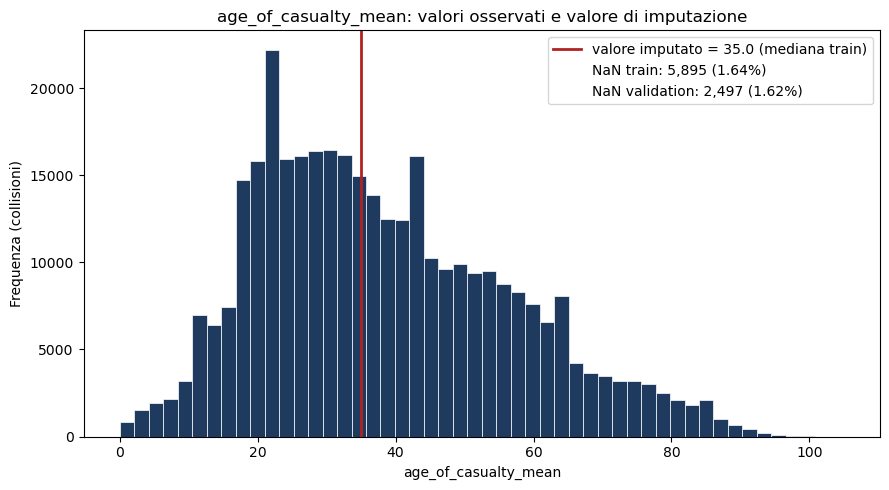

In [26]:
import matplotlib.pyplot as plt
from pathlib import Path
Path("../02_Output_grafici").mkdir(parents=True, exist_ok=True)

NAVY, RED = "#1F3A5F", "#B22222"
col = "age_of_casualty_mean"

obs = X_train[col].dropna()
med = obs.median()
n_tr, n_te = X_train[col].isna().sum(), X_test[col].isna().sum()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(obs, bins=50, color=NAVY, edgecolor="white", linewidth=0.5)
ax.axvline(med, color=RED, lw=2, label=f"valore imputato = {med:.1f} (mediana train)")
ax.plot([], [], " ", label=f"NaN train: {n_tr:,} ({n_tr / len(X_train):.2%})")
ax.plot([], [], " ", label=f"NaN validation: {n_te:,} ({n_te / len(X_test):.2%})")
ax.set_xlabel(col)
ax.set_ylabel("Frequenza (collisioni)")
ax.set_title(f"{col}: valori osservati e valore di imputazione")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("imputation_age_casualty.png", dpi=200, bbox_inches="tight")   # opzionale
plt.savefig("../02_Output_grafici/02_Missing.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
# unica colonna numerica con NaN rimasta: età media dei feriti
col = "age_of_casualty_mean"

# mediana calcolata SOLO sul train, applicata a train e test
med = X_train[col].median()
X_train[col] = X_train[col].fillna(med)
X_test[col]  = X_test[col].fillna(med)

print(f"mediana {col} (train): {med}")
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

mediana age_of_casualty_mean (train): 35.0


In [28]:
na_tr = X_train.isna().sum()
na_te = X_test.isna().sum()

na = pd.DataFrame({
    "na_train": na_tr, "%_train": (na_tr / len(X_train) * 100).round(2),
    "na_valid": na_te, "%_valid": (na_te / len(X_test) * 100).round(2),
})
na = na[(na["na_train"] > 0) | (na["na_valid"] > 0)]

print(f"NaN totali | train: {na_tr.sum():,} | validation: {na_te.sum():,}")

NaN totali | train: 0 | validation: 0


## Separation

In [29]:
y_ = y_train.squeeze().astype(int)

In [30]:
# --- Parametri ---
MIN_N = 30        # un livello conta solo se ha almeno 30 collisioni (sotto è rumore, es. 2 casi tutti gravi)
TOL = 0.005       # "separation" = tasso di target <= 0.5% oppure >= 99.5% (quasi sempre 0 o quasi sempre 1)

rows = []                                   # qui accumulo i livelli sospetti

# --- Giro su tutte le variabili del train ---
for c in X_train.columns:
    x = X_train[c]                          # la colonna corrente

    # Definisco i "livelli" della variabile:
    #  - se ha pochi valori distinti (<= 30), come le dummy 0/1, il livello è il valore stesso
    #  - se ne ha tanti (longitude, latitude, woy...), la divido in 10 fasce di uguale numerosità (decili)
    #    duplicates="drop" evita errori se più decili coincidono
    lev = x if x.nunique() <= 30 else pd.qcut(x, 10, duplicates="drop")

    # Per ogni livello calcolo: n = quante collisioni ci sono, rate = quota di target = 1 (gravi)
    # y_ è il target del train, con lo stesso indice (collision_index) di X_train
    g = y_.groupby(lev, observed=True).agg(n="size", rate="mean")

    # Scarto i livelli troppo piccoli, perché un tasso del 100% su 3 casi non dice niente
    g = g[g.n >= MIN_N]

    # Tengo i livelli "separati": tasso quasi 0 (quasi mai grave) oppure quasi 1 (quasi sempre grave)
    bad = g[(g.rate <= TOL) | (g.rate >= 1 - TOL)]

    # Per ogni livello sospetto salvo una riga con variabile, livello, numerosità e tasso
    for lv, r in bad.iterrows():
        rows.append({"var": c, "livello": lv, "n": int(r.n), "tasso_target": round(r.rate, 4)})

# --- Output ---
sep = pd.DataFrame(rows)
display(sep if len(sep) else "Nessun livello con separation")   # se non trova niente, lo dice

'Nessun livello con separation'

## Print variabili nel train

In [31]:
print(f"Training: {X_train.shape} | Validation: {X_test.shape}")

Training: (359621, 111) | Validation: (154124, 111)


In [32]:
for i in X_train.columns:
    print(i, X_train[i].dtype, X_train[i].nunique(), X_train[i].isna().sum())

longitude float64 319499 0
latitude float64 304288 0
number_of_vehicles int64 4 0
number_of_casualties int64 4 0
speed_limit int64 6 0
collision_injury_based int64 2 0
day_of_week_Weekday int64 2 0
junction_control_Auto traffic signal int64 2 0
junction_control_Give way or uncontrolled int64 2 0
junction_control_Other control int64 2 0
light_conditions_Darkness - lighting unknown int64 2 0
light_conditions_Darkness - lights lit int64 2 0
light_conditions_Darkness - no or unlit lighting int64 2 0
pedestrian_crossing_Central refuge int64 2 0
pedestrian_crossing_Human controlled int64 2 0
pedestrian_crossing_None int64 2 0
pedestrian_crossing_Signal controlled int64 2 0
pedestrian_crossing_Zebra int64 2 0
road_class_name_Local road int64 2 0
road_class_name_Main road int64 2 0
road_class_name_Minor local road int64 2 0
road_class_name_Motorway int64 2 0
road_class_name_Secondary road int64 2 0
road_surface_conditions_Dry int64 2 0
road_surface_conditions_Snow or ice int64 2 0
road_type_Du

`month` eliminata perché ridondante con `woy` (settimana ISO dell'anno), che resta come variabile stagionale.
`day_of_week_Weekday` mantenuta.

## Salvataggio X_train, y_train, X_test, y_test

In [33]:
# assert per NaN
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, "Ci sono NaN in X_train o X_test dopo l'imputazione"

In [34]:
## Salvataggio dei dataset in formato CSV
X_train.to_csv("../00_Data/Input/X_train.csv", index=True)
X_test.to_csv("../00_Data/Input/X_test.csv", index=True)
y_train.to_csv("../00_Data/Input/y_train.csv", index=True)
y_test.to_csv("../00_Data/Input/y_test.csv", index=True)